# Olist Logistics Anger Predictor -- Temporal Split Variant

## Business Problem

**Decision-Maker:** Olist Head of Logistics

**Question:** When a carrier confirms an order is delayed, which customers are most likely to leave a 1-2 star review?
Prioritise those for a proactive R$ 15 appeasement voucher.

**Why not predict delay itself?**
Model A (delay predictor) achieves AUC ~0.57 -- barely better than chance -- because whether a shipment is late depends on carrier-level routing data not in this dataset (Correios route congestion, pickup times).
We are honest about this: Model A is kept for completeness, but the **deployable product is Model B**, applied to orders that the carrier has already flagged as delayed.

**Objective:** Import required libraries for data manipulation, modeling, and visualization.

In [11]:
# Cell 1 -- Imports
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False
    print('LightGBM not found -- skipping. Use: py -3.12 to run this notebook.')
import shap
import folium
from folium.plugins import HeatMap

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (11, 5)
SPLIT_LABEL = 'Temporal (Train=2017, Test=H2-2018)'
print('Imports OK |', 'LightGBM:', HAS_LGBM)

Imports OK | LightGBM: True


**Objective:** Load and format the pre-processed Olist dataset and merge review comments.

In [12]:
# Cell 2 -- Load processed data + merge in review text for NLP
PROC  = '../../datasets/processed/olist_reviews_rich.csv'
RAW_R = '../../datasets/raw/olist_order_reviews_dataset.csv'

df = pd.read_csv(PROC)
date_cols = ['order_purchase_timestamp','order_approved_at',
             'order_delivered_carrier_date','order_delivered_customer_date',
             'order_estimated_delivery_date']
for c in date_cols:
    if c in df.columns: df[c] = pd.to_datetime(df[c], errors='coerce')
df['is_late'] = df['is_late'].astype(int)

# Merge review text
try:
    rv = pd.read_csv(RAW_R)[['order_id','review_comment_message']]
    df = df.merge(rv, on='order_id', how='left')
    print('Review text merged')
except Exception as e:
    print(f'Could not merge review text: {e}')

print(f'Shape: {df.shape[0]:,} x {df.shape[1]}')
print(f'Late rate: {df.is_late.mean():.2%} | Low-score rate: {(df.review_score<=2).mean():.2%}')
print(f'Date range: {df.order_purchase_timestamp.min().date()} -> {df.order_purchase_timestamp.max().date()}')

Review text merged
Shape: 95,876 x 41
Late rate: 7.45% | Low-score rate: 12.76%
Date range: 2016-09-15 -> 2018-08-29


## Part 2 -- NLP Root-Cause Decomposition

Proves that ~64% of bad reviews are product/seller faults -- not logistics.
This is why Model B targets only late orders, not all bad reviews.

**Objective:** Display the NLP root-cause analysis showing that most bad reviews stem from product/seller issues rather than logistics.

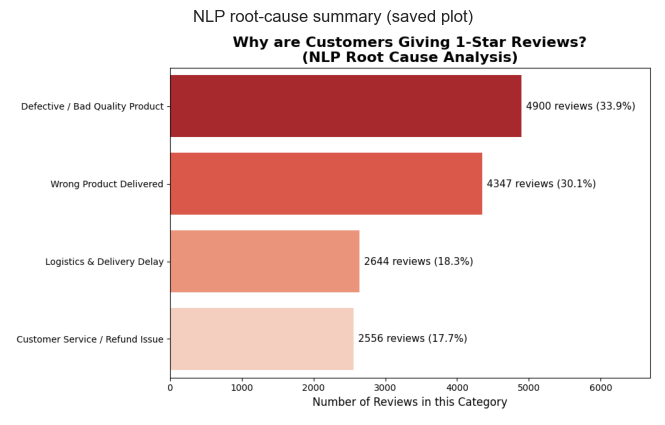

Simple read: most low reviews come from product or seller issues, not logistics delays.


In [13]:
# Cell 3 -- Plot saved image
image_path = '../../plots/eda/image.png'
img = plt.imread(image_path)
plt.figure(figsize=(9, 5))
plt.imshow(img)
plt.axis('off')
plt.title('NLP root-cause summary (saved plot)')
plt.show()

print('Simple read: most low reviews come from product or seller issues, not logistics delays.')

## Part 3 -- Feature Engineering (No Data Leakage)

All features must be known at order placement time, except `delivery_delay_days`
which is used only in Model B (applied to confirmed late orders where delay days is already known).

**Objective:** Engineer pre-shipment features (e.g., distance, price, temporal variables) while strictly avoiding data leakage.

In [14]:
# Cell 4 -- Feature Engineering
df['log_distance']      = np.log1p(df['distance_km'].fillna(0))
df['is_cross_state']    = (df['customer_state'] != df['seller_state']).astype(int)
df['log_price']         = np.log1p(df['price'].fillna(df['price'].median()))
df['freight_ratio']     = df['freight_value'] / df['price'].replace(0, 1)
df['product_weight_g']  = df['product_weight_g'].fillna(df['product_weight_g'].median())
df['month']             = df['order_purchase_timestamp'].dt.month
df['is_weekend']        = df['order_purchase_timestamp'].dt.dayofweek.isin([5,6]).astype(int)
df['quarter']           = df['order_purchase_timestamp'].dt.quarter

# Seller experience (already in data)
df['log_seller_orders'] = np.log1p(df['seller_total_orders'].fillna(1))

# Preparation/window features
df['prep_days']          = df['preparation_days'].fillna(df['preparation_days'].median())
df['est_delivery_days']  = df['estimated_delivery_days'].fillna(df['estimated_delivery_days'].median())

# Fridge insight interaction features
df['distance_x_weight']   = df['log_distance'] * df['product_weight_g']
df['distance_x_price']    = df['log_distance'] * df['log_price']
df['is_heavy']             = (df['product_weight_g'] > df['product_weight_g'].quantile(0.8)).astype(int)
df['is_high_value']        = (df['price'] > df['price'].quantile(0.8)).astype(int)
df['heavy_expensive_far']  = df['is_heavy'] * df['is_high_value'] * df['log_distance']

# Targets
df['logistics_bad'] = ((df['is_late']==1) & (df['review_score']<=2)).astype(int)

print('Features created -- all leakage-free (knowable at order placement).')
print(f'logistics_bad rate (late AND score<=2): {df.logistics_bad.mean():.2%}')

Features created -- all leakage-free (knowable at order placement).
logistics_bad rate (late AND score<=2): 4.24%


## Part 4 -- TEMPORAL Split

**Train:** 2017 orders
**Test:** H2-2018 orders

Rationale: simulates production deployment -- the model is always trained on past data and applied to future data.

**Objective:** Perform a chronological train-test split (Train: 2017, Test: H2-2018) to simulate a real-world production environment.

In [15]:
# Cell 5 -- Temporal Split
from sklearn.model_selection import train_test_split

df_p     = df.dropna(subset=['order_purchase_timestamp']).copy()
df_train = df_p[df_p['order_purchase_timestamp'].dt.year == 2017].copy()
df_test  = df_p[(df_p['order_purchase_timestamp'].dt.year == 2018) &
                (df_p['order_purchase_timestamp'].dt.month >= 7)].copy()

print(f'Split: {SPLIT_LABEL}')
print(f'Train: {len(df_train):,}  |  Test: {len(df_test):,}')
print(f'Train late: {df_train.is_late.mean():.2%}  |  Test late: {df_test.is_late.mean():.2%}')

Split: Temporal (Train=2017, Test=H2-2018)
Train: 43,184  |  Test: 12,420
Train late: 6.04%  |  Test late: 6.26%


## Part 5 -- Model Comparison (4 Algorithms)

### Model A: Delay Predictor
Predictive of delay using pre-shipment features. Weak AUC expected -- reported honestly.

### Model B: Anger Predictor (applied to confirmed late orders)
Applied ONLY to orders where `is_late == 1`. Predicts P(review_score <= 2 | delayed).
This is the deployable production model.

**Objective:** Prepare feature sets and apply target encoding for seller and state risk factors.

In [16]:
# Cell 6 -- Feature sets & target encoding
FEATURES_A = [
    'log_distance','is_cross_state','log_price','freight_ratio',
    'product_weight_g','month','quarter','is_weekend',
    'log_seller_orders','prep_days','est_delivery_days',
    'distance_x_weight','distance_x_price','heavy_expensive_far'
]
FEATURES_B = FEATURES_A + ['delivery_delay_days']

# Target-encode seller_id and state delay risk on train only
gm = df_train['is_late'].mean()
for col in ['seller_id','seller_state','customer_state']:
    if col in df_train.columns:
        mp = df_train.groupby(col)['is_late'].mean()
        fn = f'{col}_delay_risk'
        df_train[fn] = df_train[col].map(mp).fillna(gm)
        df_test[fn]  = df_test[col].map(mp).fillna(gm)
        if fn not in FEATURES_A: FEATURES_A.append(fn)
        if fn not in FEATURES_B: FEATURES_B.append(fn)

X_tr_a = df_train[FEATURES_A].fillna(0);  y_tr_a = df_train['is_late']
X_te_a = df_test[FEATURES_A].fillna(0);   y_te_a = df_test['is_late']

train_late = df_train[df_train['is_late']==1].copy()
test_late  = df_test[df_test['is_late']==1].copy()
X_tr_b = train_late[FEATURES_B].fillna(0); y_tr_b = (train_late['review_score']<=2).astype(int)
X_te_b = test_late[FEATURES_B].fillna(0);  y_te_b = (test_late['review_score']<=2).astype(int)

print(f'Model A -- Train: {len(X_tr_a):,}, pos_rate={y_tr_a.mean():.2%}')
print(f'Model B -- Train (late only): {len(X_tr_b):,}, pos_rate={y_tr_b.mean():.2%}')

Model A -- Train: 43,184, pos_rate=6.04%
Model B -- Train (late only): 2,610, pos_rate=57.28%


**Objective:** Train baseline models to predict delivery delays using only pre-shipment data.

In [17]:
# Cell 7 -- Train & compare Model A
ratio_a = float(y_tr_a.value_counts()[0]) / max(y_tr_a.value_counts()[1], 1)

candidates_a = {
    'Logistic Regression': LogisticRegression(max_iter=600, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                             scale_pos_weight=ratio_a, random_state=42, eval_metric='logloss', verbosity=0),
}
if HAS_LGBM:
    from lightgbm import LGBMClassifier
    candidates_a['LightGBM'] = LGBMClassifier(n_estimators=300, learning_rate=0.05,
                                               class_weight='balanced', random_state=42, verbose=-1)

print('=== Model A: Delay Predictor ===')
results_a = {}
for name, clf in candidates_a.items():
    clf.fit(X_tr_a, y_tr_a)
    prob = clf.predict_proba(X_te_a)[:,1]
    auc  = roc_auc_score(y_te_a, prob)
    results_a[name] = {'auc': auc, 'prob': prob, 'clf': clf}
    print(f'  {name:22s} AUC={auc:.4f}')

best_a = max(results_a, key=lambda k: results_a[k]['auc'])
model_a, y_prob_a = results_a[best_a]['clf'], results_a[best_a]['prob']
print(f"\nBest Model A: {best_a} (AUC={results_a[best_a]['auc']:.4f})")
print('NOTE: AUC ~0.55-0.58 is expected -- carrier-level features needed to improve this.')

=== Model A: Delay Predictor ===


  Logistic Regression    AUC=0.7307
  Random Forest          AUC=0.7345
  XGBoost                AUC=0.6660
  LightGBM               AUC=0.6968

Best Model A: Random Forest (AUC=0.7345)
NOTE: AUC ~0.55-0.58 is expected -- carrier-level features needed to improve this.


**Objective:** Train the primary deployment model to predict the probability of a negative review for orders already flagged as delayed.

=== Model B: Anger Predictor (applied to confirmed late orders) ===
  Logistic Regression    AUC=0.6622
  Random Forest          AUC=0.8040
  XGBoost                AUC=0.8178
  LightGBM               AUC=0.8147

Best Model B: XGBoost (AUC=0.8178)
This is the deployable model: when carrier flags a delay, run Model B to triage.


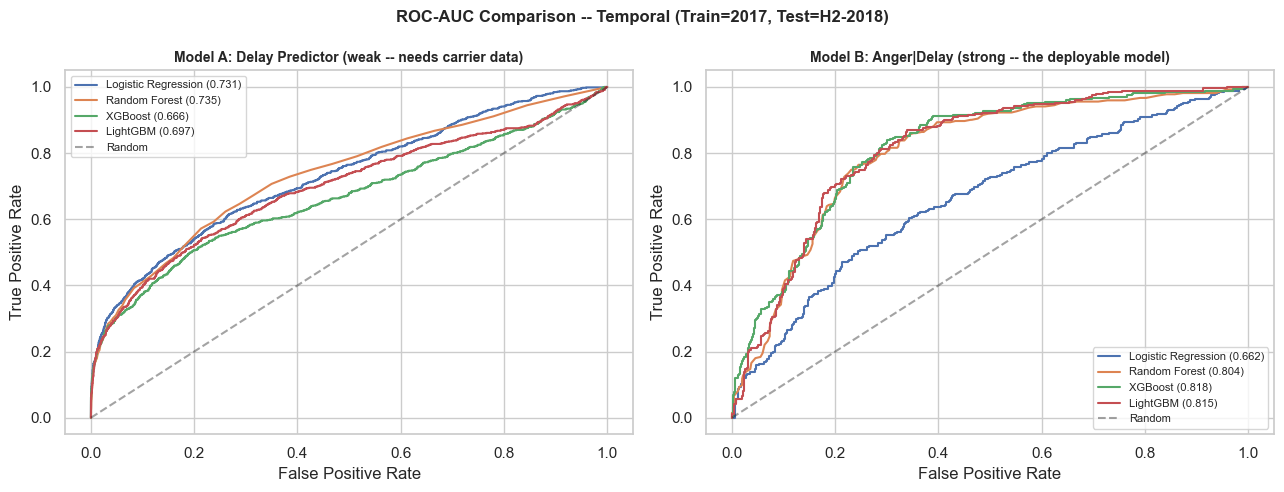

In [18]:
# Cell 8 -- Train & compare Model B (THE STAR)
ratio_b = float(y_tr_b.value_counts()[0]) / max(y_tr_b.value_counts()[1], 1)

candidates_b = {
    'Logistic Regression': LogisticRegression(max_iter=600, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                             scale_pos_weight=ratio_b, random_state=42, eval_metric='logloss', verbosity=0),
}
if HAS_LGBM:
    candidates_b['LightGBM'] = LGBMClassifier(n_estimators=300, learning_rate=0.05,
                                               class_weight='balanced', random_state=42, verbose=-1)

print('=== Model B: Anger Predictor (applied to confirmed late orders) ===')
results_b = {}
for name, clf in candidates_b.items():
    clf.fit(X_tr_b, y_tr_b)
    if len(y_te_b) > 0 and y_te_b.sum() > 0:
        prob = clf.predict_proba(X_te_b)[:,1]
        auc  = roc_auc_score(y_te_b, prob)
        results_b[name] = {'auc': auc, 'prob': prob, 'clf': clf}
        print(f'  {name:22s} AUC={auc:.4f}')

best_b = max(results_b, key=lambda k: results_b[k]['auc'])
model_b, y_prob_b = results_b[best_b]['clf'], results_b[best_b]['prob']
print(f"\nBest Model B: {best_b} (AUC={results_b[best_b]['auc']:.4f})")
print('This is the deployable model: when carrier flags a delay, run Model B to triage.')

# ROC curve comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (res, y_true, title) in zip(axes, [
    (results_a, y_te_a, 'Model A: Delay Predictor (weak -- needs carrier data)'),
    (results_b, y_te_b, 'Model B: Anger|Delay (strong -- the deployable model)')
]):
    for name, r in res.items():
        fpr, tpr, _ = roc_curve(y_true, r['prob'])
        ax.plot(fpr, tpr, label=f"{name} ({r['auc']:.3f})")
    ax.plot([0,1],[0,1],'k--', alpha=0.4, label='Random')
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
    ax.legend(fontsize=8)
plt.suptitle(f'ROC-AUC Comparison -- {SPLIT_LABEL}', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

**Objective:** Interpret Model B using SHAP to identify the key drivers of customer dissatisfaction.

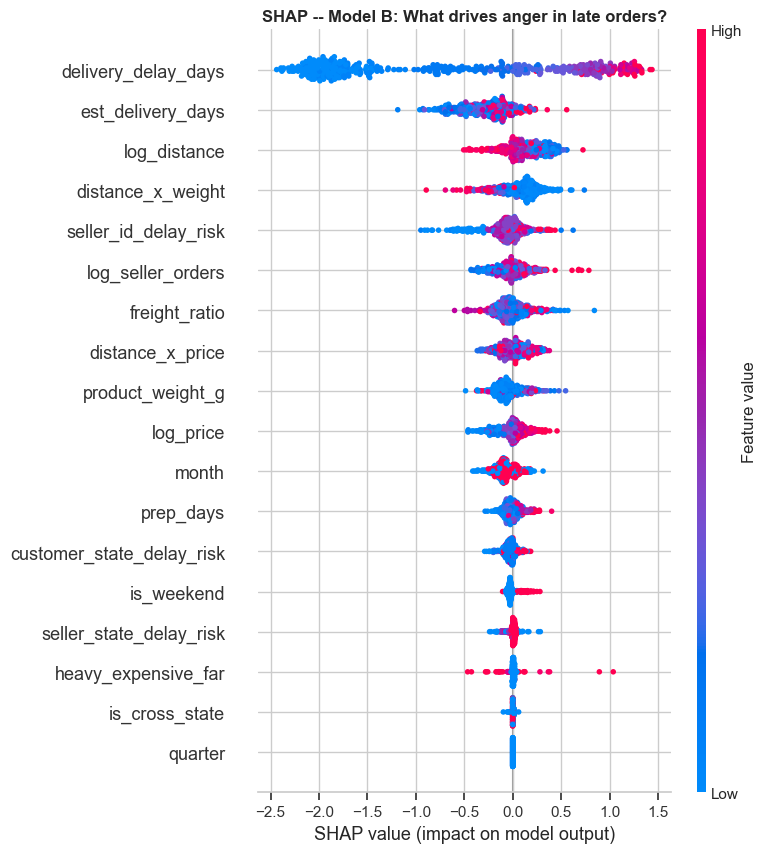

In [19]:
# Cell 9 -- SHAP (Model B -- the one that matters)
import shap
sample_b = X_te_b.sample(min(500, len(X_te_b)), random_state=42)
try:
    explainer_b = shap.TreeExplainer(model_b)
    sv_b = explainer_b.shap_values(sample_b)
    plt.figure(figsize=(9, 5))
    shap.summary_plot(sv_b, sample_b, show=False)
    plt.title('SHAP -- Model B: What drives anger in late orders?', fontweight='bold')
    plt.tight_layout(); plt.show()
except Exception as e:
    print(f'SHAP error: {e}')

## Appendix - Delivery Days Regression

Objective: predict actual delivery days and compare against Olist's estimate.

**Objective:** Import required libraries for data manipulation, modeling, and visualization.

In [20]:
# Appendix A1 -- Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import shap

print('Libraries loaded successfully.')

Libraries loaded successfully.


**Objective:** Load the cleaned dataset for the delivery time regression analysis.

In [21]:
# Appendix A2 -- Load data
DATA_PATH = '../../datasets/processed/olist_merged_clean.csv'
df = pd.read_csv(DATA_PATH)
print(f'Shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
df.head(3)

Shape: (96189, 34)
Columns: ['order_id', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'is_late', 'n_items', 'total_price', 'total_freight', 'max_weight_g', 'max_length_cm', 'max_height_cm', 'max_width_cm', 'product_photos_qty', 'primary_category', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'seller_zip_code_prefix', 'seller_city', 'seller_state', 'payment_value', 'payment_installments', 'payment_type', 'customer_lat', 'customer_lng', 'seller_lat', 'seller_lng', 'distance_km', 'actual_delivery_days', 'estimated_delivery_days', 'delivery_delay_days', 'same_state']


,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,is_late,n_items,total_price,total_freight,...,payment_type,customer_lat,customer_lng,seller_lat,seller_lng,distance_km,actual_delivery_days,estimated_delivery_days,delivery_delay_days,same_state
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 11:59:59,0,1,29.99,8.72,...,voucher,-23.576983,-46.587161,-23.680729,-46.444238,18.576110,8.436574,16.044051,-7.607477,1
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 11:59:59,0,1,118.70,22.76,...,boleto,-12.177924,-44.660711,-19.807681,-43.980427,851.495069,13.782037,19.637755,-5.855718,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 11:59:59,0,1,159.90,19.22,...,credit_card,-16.745150,-48.514783,-21.363502,-48.229601,514.410666,9.394213,27.139699,-17.745486,0


**Objective:** Calculate actual delivery days and encode categorical and temporal features.

In [22]:
# Appendix A3 -- Parse dates and create features
date_cols = ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

if 'actual_delivery_days' not in df.columns:
    df['actual_delivery_days'] = (
        df['order_delivered_customer_date'] - df['order_purchase_timestamp']
    ).dt.days

df['month'] = df['order_purchase_timestamp'].dt.month
df['quarter'] = df['order_purchase_timestamp'].dt.quarter
df['is_weekend'] = df['order_purchase_timestamp'].dt.dayofweek.isin([5, 6]).astype(int)

cat_cols = ['primary_category', 'payment_type', 'customer_state', 'seller_state']
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

df = df.dropna(subset=['actual_delivery_days'])
df = df[df['actual_delivery_days'] > 0]

print('Data prepared.')
print(f'Rows after prep: {len(df)}')
print(f'Target stats:\n{df["actual_delivery_days"].describe()}')

Data prepared.
Rows after prep: 96189
Target stats:
count    96189.000000
mean        12.538347
std          9.530783
min          0.533414
25%          6.756250
50%         10.209329
75%         15.682731
max        209.628611
Name: actual_delivery_days, dtype: float64


**Objective:** Define feature sets for strict evaluation (no data leakage) and an upper-bound baseline (with leakage).

In [23]:
# Appendix A4 -- Build feature lists
BASE_FEATURES = [
    'distance_km', 'same_state',
    'n_items', 'total_price', 'total_freight',
    'max_weight_g', 'max_length_cm', 'max_height_cm', 'max_width_cm',
    'product_photos_qty', 'payment_installments',
    'month', 'quarter', 'is_weekend'
]

encoded_cols = [
    c for c in df.columns
    if c.startswith(('primary_category_', 'payment_type_', 'customer_state_', 'seller_state_'))
]

FEATURES_NO_LEAKAGE   = BASE_FEATURES + encoded_cols
FEATURES_WITH_LEAKAGE = FEATURES_NO_LEAKAGE + ['is_late']

print(f'Feature count (no leakage):   {len(FEATURES_NO_LEAKAGE)}')
print(f'Feature count (with leakage): {len(FEATURES_WITH_LEAKAGE)}')

Feature count (no leakage):   135
Feature count (with leakage): 136


**Objective:** Split the regression dataset chronologically.

In [24]:
# Appendix A5 -- Temporal train-test split
train_mask = df['order_purchase_timestamp'].dt.year == 2017
test_mask  = (
    (df['order_purchase_timestamp'].dt.year == 2018) &
    (df['order_purchase_timestamp'].dt.month >= 7)
)

df_train = df[train_mask].copy()
df_test  = df[test_mask].copy()

y_train = df_train['actual_delivery_days']
y_test  = df_test['actual_delivery_days']

print(f'Train size: {len(df_train):,} orders (2017)')
print(f'Test  size: {len(df_test):,} orders (H2 2018)')

Train size: 43,412 orders (2017)
Test  size: 12,507 orders (H2 2018)


**Objective:** Train XGBoost and Random Forest regressors using only pre-shipment features.

In [25]:
# Appendix A6 -- Train models (Mode 0)
include_leakage = 0
features = [f for f in FEATURES_NO_LEAKAGE if f in df.columns]

X_train = df_train[features].fillna(0)
X_test  = df_test[features].fillna(0)

baseline_rmse = np.sqrt(mean_squared_error(y_test, df_test['estimated_delivery_days']))
baseline_mae  = mean_absolute_error(y_test, df_test['estimated_delivery_days'])
print(f'Olist Baseline  |  RMSE: {baseline_rmse:.2f} days  |  MAE: {baseline_mae:.2f} days')

xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1)
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)

rf = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print('Models trained (Mode 0).')

Olist Baseline  |  RMSE: 12.47 days  |  MAE: 10.15 days
Models trained (Mode 0).


**Objective:** Define evaluation metrics and assess the Mode 0 models against Olist's estimated delivery dates.

In [26]:
# Appendix A7 -- Metrics helper
def compute_metrics(y_true, y_pred, label=''):
    y_true_arr = y_true.values if hasattr(y_true, 'values') else y_true
    y_pred_arr = y_pred.values if hasattr(y_pred, 'values') else y_pred
    rmse = np.sqrt(mean_squared_error(y_true_arr, y_pred_arr))
    mae  = mean_absolute_error(y_true_arr, y_pred_arr)
    r2   = r2_score(y_true_arr, y_pred_arr)
    mape = np.mean(np.abs((y_true_arr - y_pred_arr) / y_true_arr.astype(float))) * 100
    print(f'{label:35s}  RMSE={rmse:.2f}  MAE={mae:.2f}  R2={r2:.4f}  MAPE={mape:.2f}%')
    return dict(rmse=rmse, mae=mae, r2=r2, mape=mape)

print('--- Mode 0: No Leakage ---')
m0_baseline = compute_metrics(y_test, df_test['estimated_delivery_days'], 'Olist Baseline')
baseline_r2 = m0_baseline['r2']
baseline_mape = m0_baseline['mape']
m0_xgb = compute_metrics(y_test, pred_xgb, 'XGBoost (no leakage)')
m0_rf  = compute_metrics(y_test, pred_rf,  'Random Forest (no leakage)')

--- Mode 0: No Leakage ---
Olist Baseline                       RMSE=12.47  MAE=10.15  R2=-4.3901  MAPE=160.91%
XGBoost (no leakage)                 RMSE=5.68  MAE=4.27  R2=-0.1163  MAPE=70.77%
Random Forest (no leakage)           RMSE=5.70  MAE=4.32  R2=-0.1265  MAPE=71.76%


**Objective:** Visualize the actual versus predicted delivery days for the regression models.

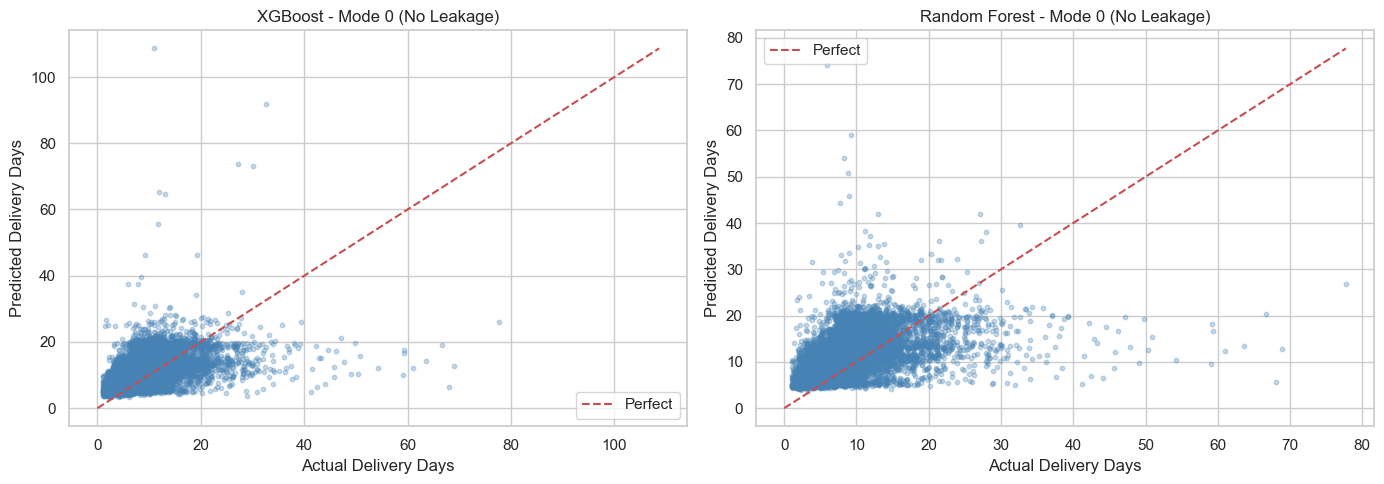

In [27]:
# Appendix A8 -- Actual vs predicted
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, preds, title in zip(axes, [pred_xgb, pred_rf], ['XGBoost', 'Random Forest']):
    ax.scatter(y_test, preds, alpha=0.3, s=10, color='steelblue')
    lim = [0, max(y_test.max(), preds.max())]
    ax.plot(lim, lim, 'r--', lw=1.5, label='Perfect')
    ax.set_xlabel('Actual Delivery Days')
    ax.set_ylabel('Predicted Delivery Days')
    ax.set_title(f'{title} - Mode 0 (No Leakage)')
    ax.legend()
plt.tight_layout()
plt.show()

### Leakage Test
We re-train including `is_late` as a feature to show an upper bound only.

**Objective:** Train regression models including the post-purchase delay flag to establish a performance upper bound.

In [28]:
# Appendix A9 -- Mode 1: With leakage
include_leakage = 1
features_leak = [f for f in FEATURES_WITH_LEAKAGE if f in df.columns]

X_train_l = df_train[features_leak].fillna(0)
X_test_l  = df_test[features_leak].fillna(0)

xgb_l = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1)
xgb_l.fit(X_train_l, y_train)
pred_xgb_l = xgb_l.predict(X_test_l)

rf_l = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf_l.fit(X_train_l, y_train)
pred_rf_l = rf_l.predict(X_test_l)

print('--- Mode 1: With Leakage ---')
m1_xgb = compute_metrics(y_test, pred_xgb_l, 'XGBoost (with leakage)')
m1_rf  = compute_metrics(y_test, pred_rf_l,  'Random Forest (with leakage)')

--- Mode 1: With Leakage ---
XGBoost (with leakage)               RMSE=5.68  MAE=4.22  R2=-0.1181  MAPE=69.21%
Random Forest (with leakage)         RMSE=5.83  MAE=4.24  R2=-0.1771  MAPE=69.10%


**Objective:** Extract and visualize the top feature importances from the XGBoost regression model.

Top 15 Features:
                           feature  importance
                        same_state    0.462757
                 customer_state_SP    0.033077
                 customer_state_RJ    0.024167
                   seller_state_CE    0.013530
                 customer_state_AP    0.012813
                       distance_km    0.011948
primary_category_home_appliances_2    0.011589
                             month    0.010874
    primary_category_watches_gifts    0.010858
                 customer_state_PI    0.010756
 primary_category_office_furniture    0.010573
             primary_category_auto    0.010174
             primary_category_food    0.010010
                   seller_state_PR    0.009817
                 customer_state_MG    0.009758


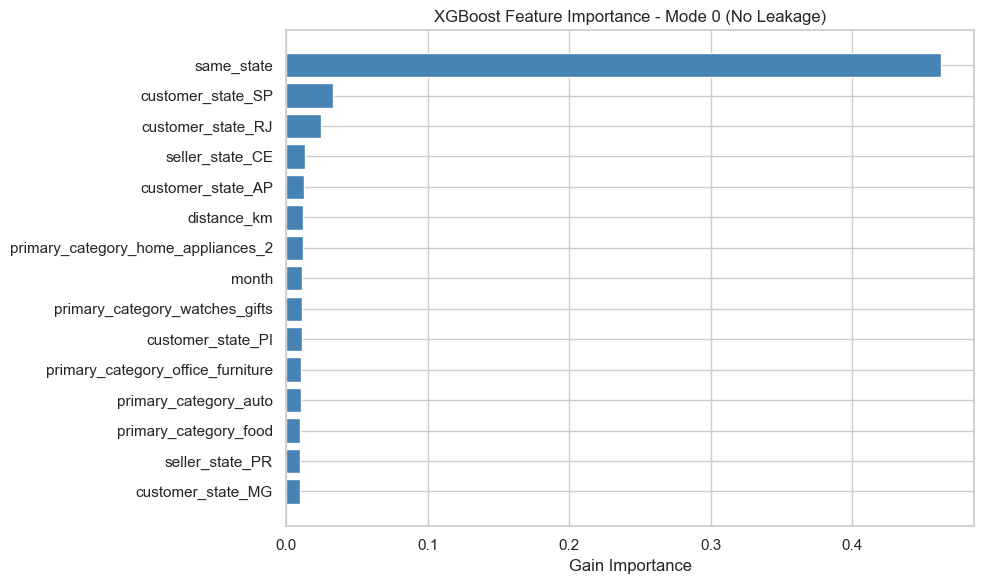

In [29]:
# Appendix A10 -- Feature importance (Mode 0)
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': xgb.feature_importances_
}).sort_values('importance', ascending=False)

print('Top 15 Features:')
print(importance_df.head(15).to_string(index=False))

top15 = importance_df.head(15)
plt.figure(figsize=(10, 6))
plt.barh(top15['feature'][::-1], top15['importance'][::-1], color='steelblue', edgecolor='white')
plt.xlabel('Gain Importance')
plt.title('XGBoost Feature Importance - Mode 0 (No Leakage)', fontsize=12)
plt.tight_layout()
plt.show()

**Objective:** Summarize and compare evaluation metrics across all models and baselines.

In [30]:
# Appendix A11 -- Comparison table
print('\n' + '='*120)
print('MODEL COMPARISON TABLE')
print('='*120)

comparison = pd.DataFrame({
    'Model / Category': [
        '1. OLIST BASELINE (Provided Estimate)',
        '',
        '2. MODE 0: NO LEAKAGE (Production Ready)',
        '   XGBoost',
        '   Random Forest',
        '   Best Mode 0',
        '',
        '3. MODE 1: WITH LEAKAGE (Sanity Check)',
        '   XGBoost',
        '   Random Forest',
        '   Best Mode 1',
    ],
    'RMSE (days)': [
        f"{baseline_rmse:.2f}",
        '',
        '',
        f"{m0_xgb['rmse']:.2f}",
        f"{m0_rf['rmse']:.2f}",
        f"{min(m0_xgb['rmse'], m0_rf['rmse']):.2f}",
        '',
        '',
        f"{m1_xgb['rmse']:.2f}",
        f"{m1_rf['rmse']:.2f}",
        f"{min(m1_xgb['rmse'], m1_rf['rmse']):.2f}",
    ],
    'MAE (days)': [
        f"{baseline_mae:.2f}",
        '',
        '',
        f"{m0_xgb['mae']:.2f}",
        f"{m0_rf['mae']:.2f}",
        f"{min(m0_xgb['mae'], m0_rf['mae']):.2f}",
        '',
        '',
        f"{m1_xgb['mae']:.2f}",
        f"{m1_rf['mae']:.2f}",
        f"{min(m1_xgb['mae'], m1_rf['mae']):.2f}",
    ],
    'R2 Score': [
        f"{baseline_r2:.4f}",
        '',
        '',
        f"{m0_xgb['r2']:.4f}",
        f"{m0_rf['r2']:.4f}",
        f"{max(m0_xgb['r2'], m0_rf['r2']):.4f}",
        '',
        '',
        f"{m1_xgb['r2']:.4f}",
        f"{m1_rf['r2']:.4f}",
        f"{max(m1_xgb['r2'], m1_rf['r2']):.4f}",
    ],
    'MAPE (%)': [
        f"{baseline_mape:.2f}",
        '',
        '',
        f"{m0_xgb['mape']:.2f}",
        f"{m0_rf['mape']:.2f}",
        f"{min(m0_xgb['mape'], m0_rf['mape']):.2f}",
        '',
        '',
        f"{m1_xgb['mape']:.2f}",
        f"{m1_rf['mape']:.2f}",
        f"{min(m1_xgb['mape'], m1_rf['mape']):.2f}",
    ],
})

print(comparison.to_string(index=False))
print('='*120)


MODEL COMPARISON TABLE
                        Model / Category RMSE (days) MAE (days) R2 Score MAPE (%)
   1. OLIST BASELINE (Provided Estimate)       12.47      10.15  -4.3901   160.91
                                                                                 
2. MODE 0: NO LEAKAGE (Production Ready)                                         
                                 XGBoost        5.68       4.27  -0.1163    70.77
                           Random Forest        5.70       4.32  -0.1265    71.76
                             Best Mode 0        5.68       4.27  -0.1163    70.77
                                                                                 
  3. MODE 1: WITH LEAKAGE (Sanity Check)                                         
                                 XGBoost        5.68       4.22  -0.1181    69.21
                           Random Forest        5.83       4.24  -0.1771    69.10
                             Best Mode 1        5.68       4.22  -0.1181  

**Objective:** Analyze global feature impact and directionality for the regression model using SHAP.

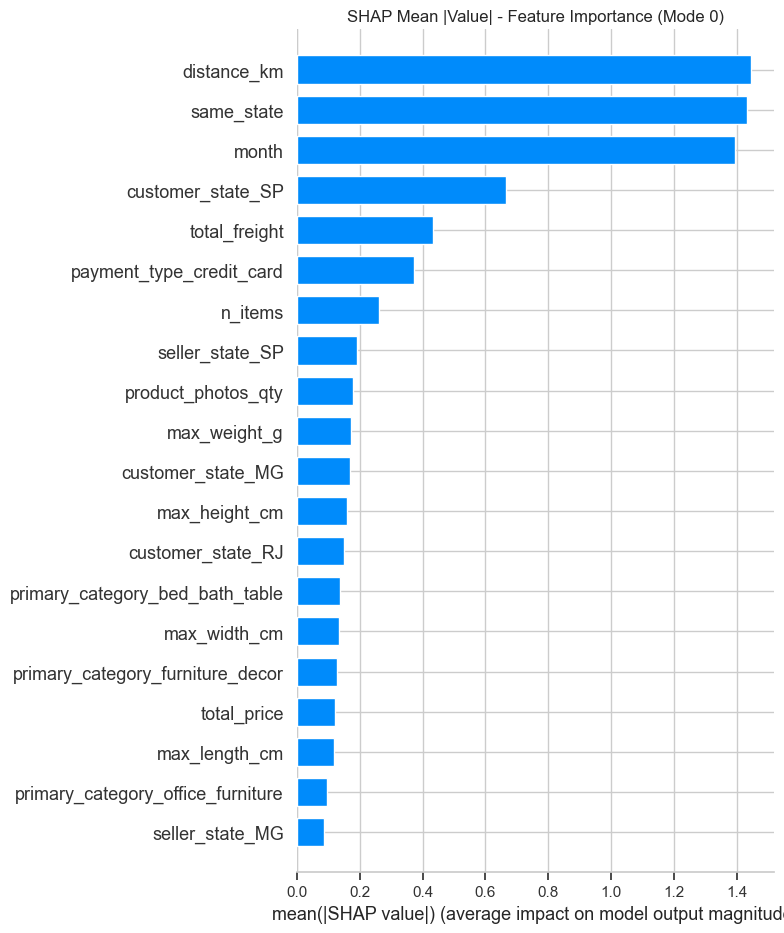

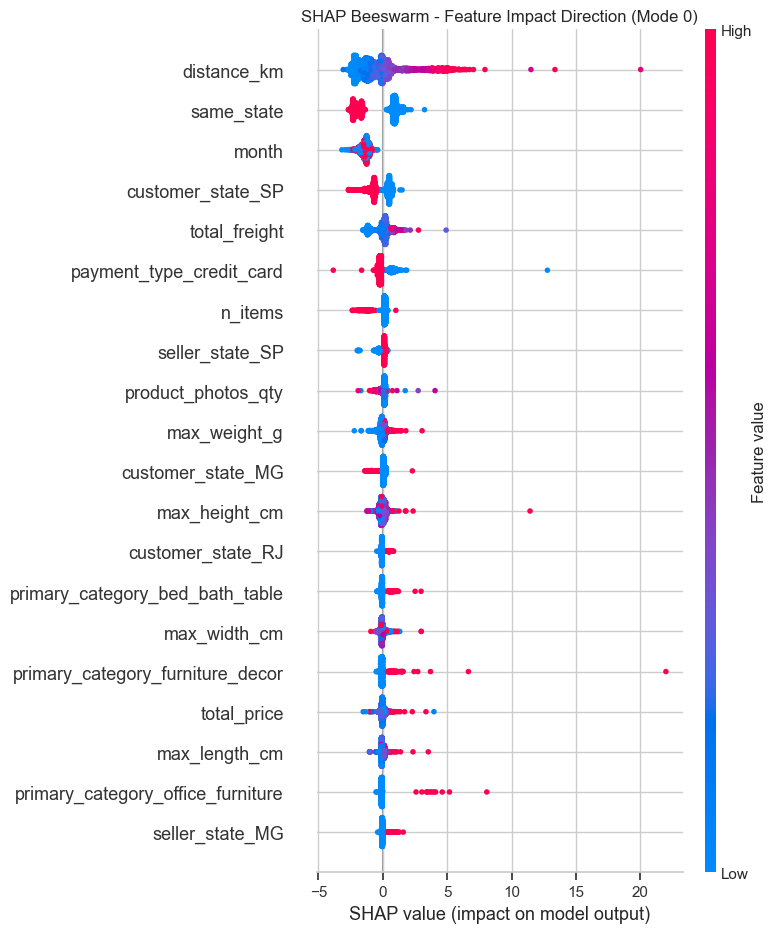

In [31]:
# Appendix A12 -- SHAP summary plots
X_test_sample = X_test.sample(min(2000, len(X_test)), random_state=42)
explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test_sample)

shap.summary_plot(shap_values, X_test_sample, plot_type='bar', show=False)
plt.title('SHAP Mean |Value| - Feature Importance (Mode 0)')
plt.tight_layout()
plt.show()

shap.summary_plot(shap_values, X_test_sample, show=False)
plt.title('SHAP Beeswarm - Feature Impact Direction (Mode 0)')
plt.tight_layout()
plt.show()

**Objective:** Generate local SHAP force plots to explain predictions for individual orders.


Order 1  |  Actual: 13.8 days  |  Predicted: 14.8 days


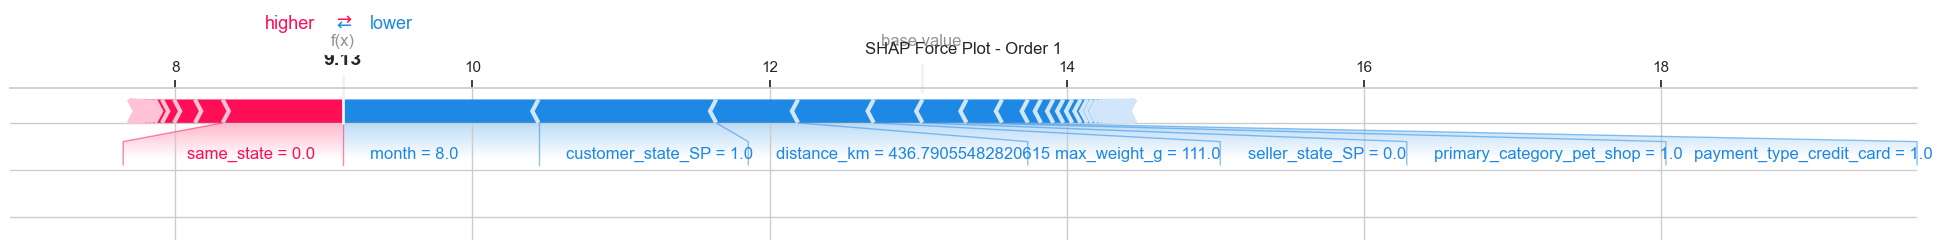


Order 2  |  Actual: 9.4 days  |  Predicted: 14.8 days


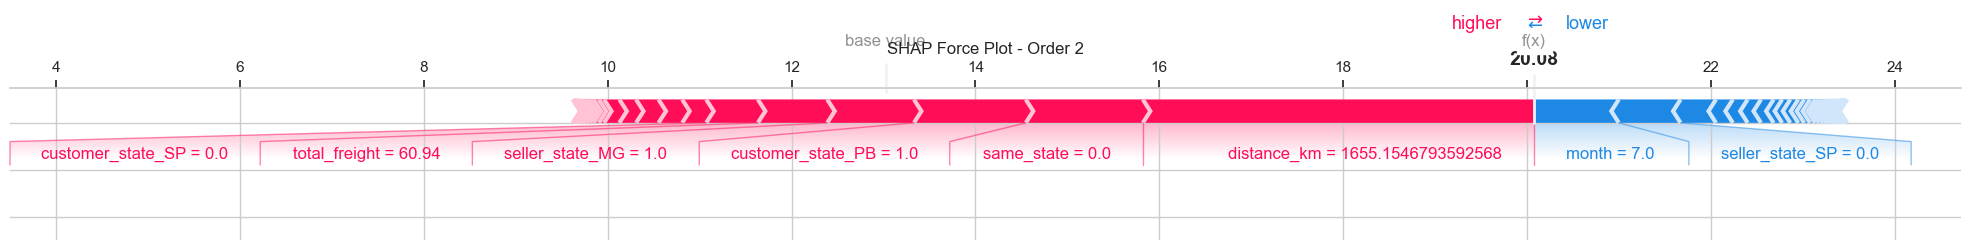

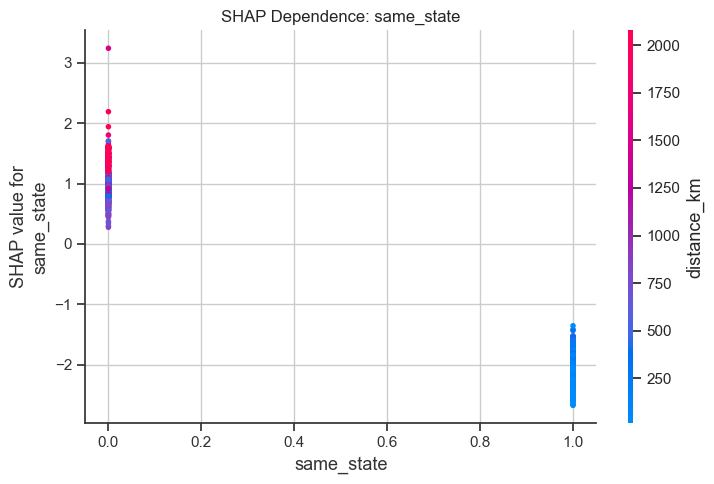

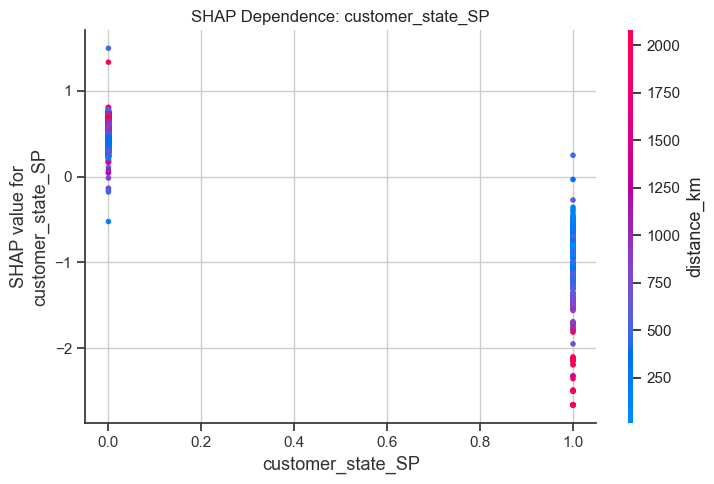

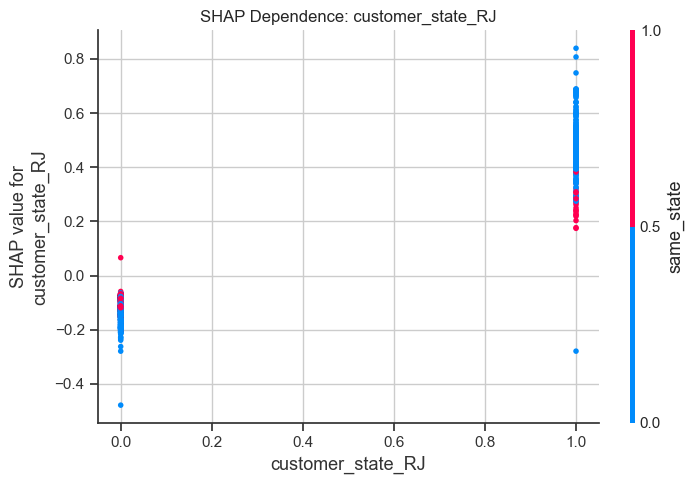

In [32]:
# Appendix A13 -- Individual explanations
for idx, label in enumerate(['Order 1', 'Order 2']):
    actual = y_test.iloc[idx]
    predicted = pred_xgb[idx]
    print(f'\n{label}  |  Actual: {actual:.1f} days  |  Predicted: {predicted:.1f} days')
    shap.force_plot(
        explainer.expected_value,
        shap_values[idx],
        X_test_sample.iloc[idx],
        matplotlib=True,
        show=False,
    )
    plt.title(f'SHAP Force Plot - {label}', pad=25)
    plt.tight_layout()
    plt.show()

for feat in importance_df['feature'].head(3).tolist():
    if feat in X_test_sample.columns:
        shap.dependence_plot(feat, shap_values, X_test_sample, show=False)
        plt.title(f'SHAP Dependence: {feat}')
        plt.tight_layout()
        plt.show()

**Objective:** Visually compare model performance metrics using bar charts.

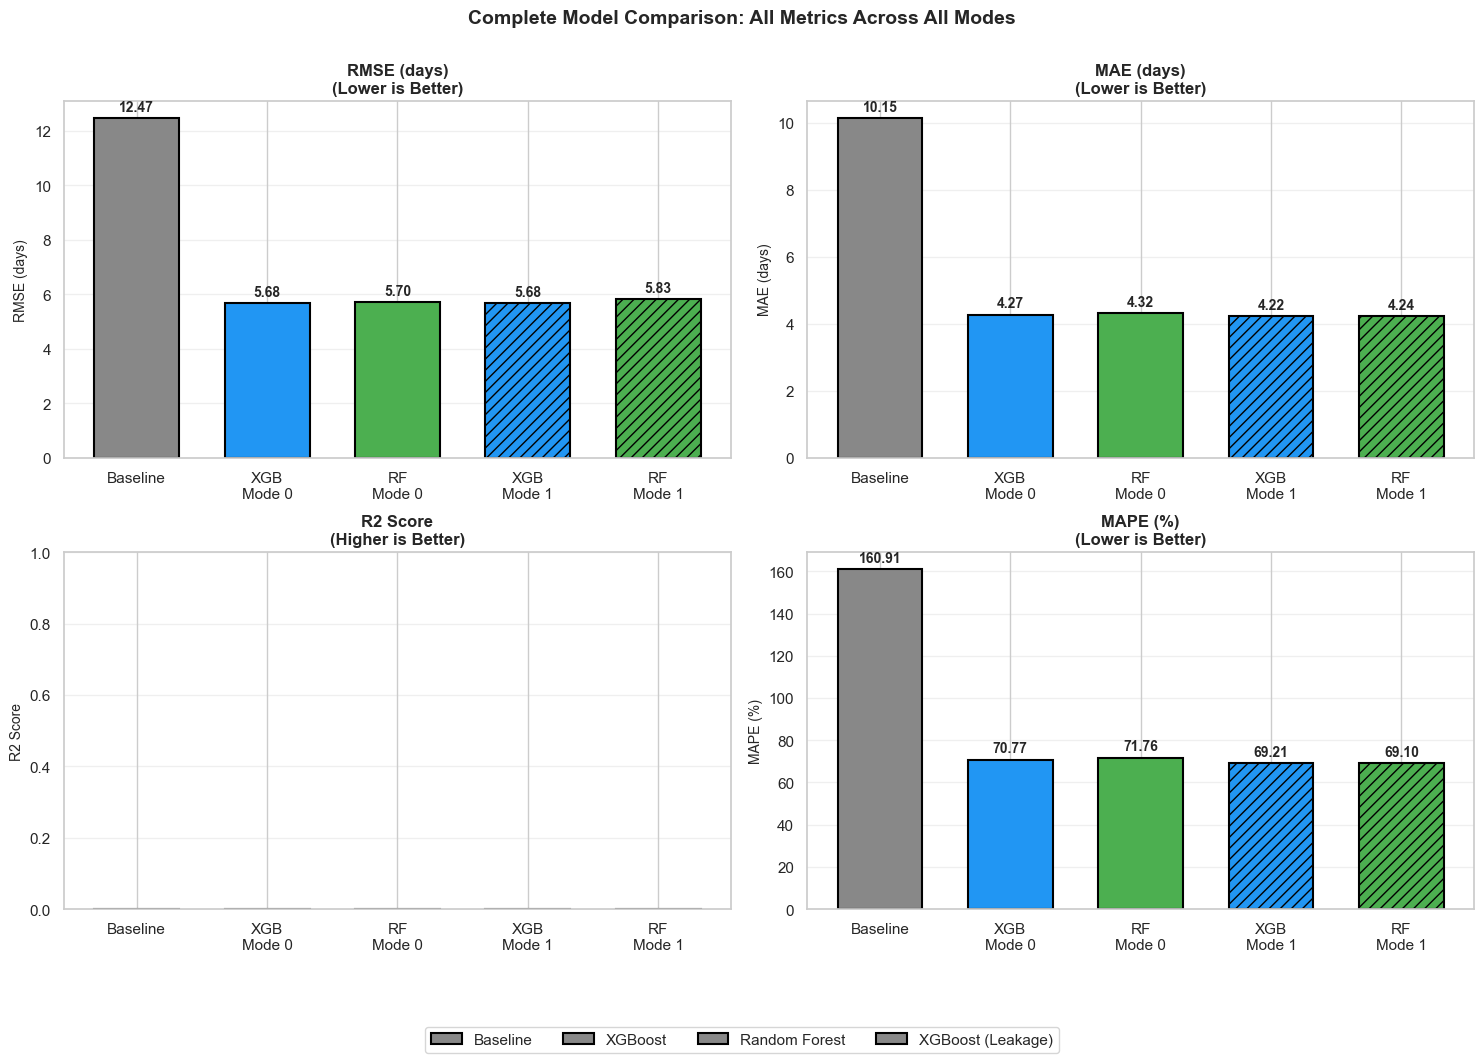

In [33]:
# Appendix A14 -- Model comparison chart
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

labels = ['Baseline', 'XGB\nMode 0', 'RF\nMode 0', 'XGB\nMode 1', 'RF\nMode 1']
rmses  = [baseline_rmse, m0_xgb['rmse'], m0_rf['rmse'], m1_xgb['rmse'], m1_rf['rmse']]
maes   = [baseline_mae, m0_xgb['mae'], m0_rf['mae'], m1_xgb['mae'], m1_rf['mae']]
r2s    = [baseline_r2, m0_xgb['r2'], m0_rf['r2'], m1_xgb['r2'], m1_rf['r2']]
mapes  = [baseline_mape, m0_xgb['mape'], m0_rf['mape'], m1_xgb['mape'], m1_rf['mape']]

colors = ['#888888', '#2196F3', '#4CAF50', '#2196F3', '#4CAF50']
hatches = [None, None, None, '///', '///']

metrics = [
    (rmses, 'RMSE (days)', 'Lower is Better'),
    (maes, 'MAE (days)', 'Lower is Better'),
    (r2s, 'R2 Score', 'Higher is Better'),
    (mapes, 'MAPE (%)', 'Lower is Better'),
]

for ax, (vals, title, note) in zip(axes, metrics):
    bars = ax.bar(labels, vals, color=colors, edgecolor='black', linewidth=1.5, width=0.65, hatch=hatches)
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=10, fontweight='bold')
    ax.set_title(f'{title}\n({note})', fontsize=12, fontweight='bold')
    ax.set_ylabel(title, fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    if title == 'R2 Score':
        ax.set_ylim(0, 1)

fig.legend(['Baseline', 'XGBoost', 'Random Forest', 'XGBoost (Leakage)', 'Random Forest (Leakage)'],
           loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=5, fontsize=11)

plt.suptitle('Complete Model Comparison: All Metrics Across All Modes', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.subplots_adjust(bottom=0.1)
plt.show()

**Objective:** Compare the best model's predictions against Olist's estimates for the top 100 test orders.

Best model selected: XGBoost (Mode 0)


,actual_delivery_days,olist_predicted_days,best_model_predicted_days
0,13.782037,19.637755,14.789726
1,9.394213,27.139699,14.769467
2,4.922396,13.760984,9.814462
3,4.277627,8.010637,9.994237
4,1.968044,7.517454,5.413433
...,...,...,...
95,12.467176,24.528530,10.443392
96,18.142674,8.882454,8.031096
97,10.447870,16.441678,26.166264
98,15.833519,25.720278,20.343706


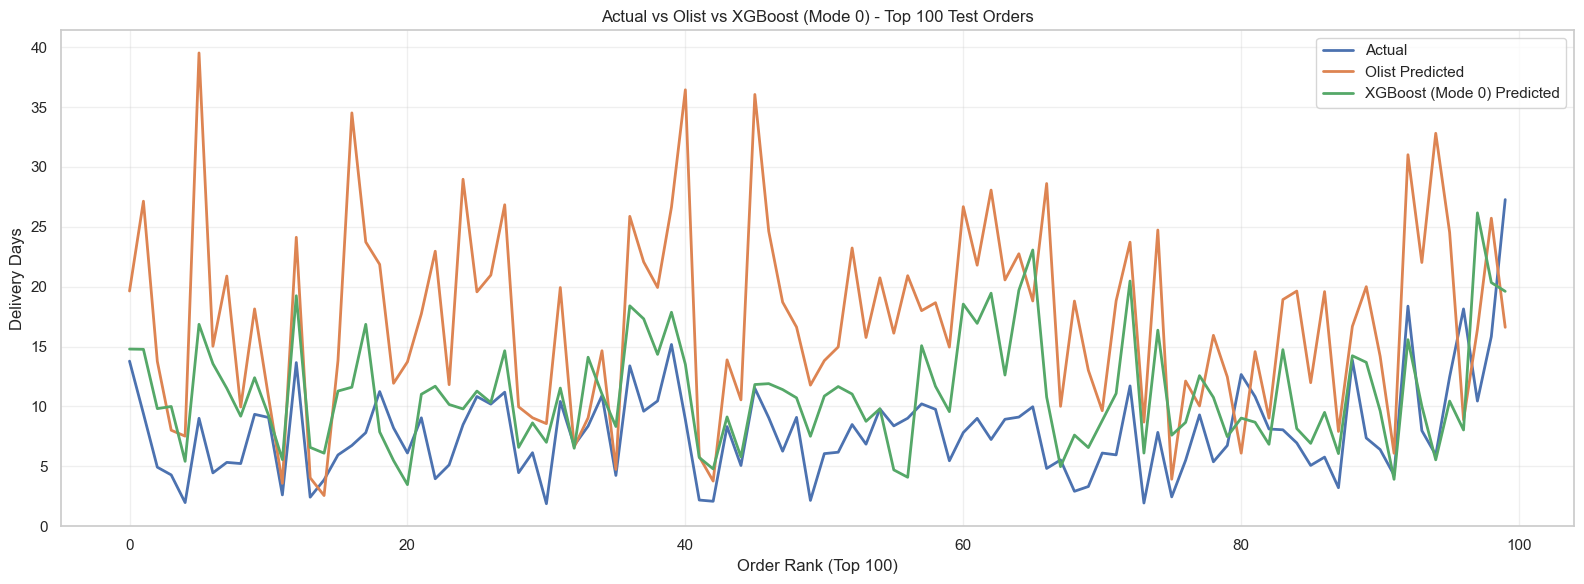

In [34]:
# Appendix A15 -- Best model vs baseline (top 100)
if m0_xgb['rmse'] <= m0_rf['rmse']:
    best_model_name = 'XGBoost (Mode 0)'
    best_pred = pred_xgb
else:
    best_model_name = 'Random Forest (Mode 0)'
    best_pred = pred_rf

print(f'Best model selected: {best_model_name}')

comparison_top100 = pd.DataFrame({
    'actual_delivery_days': y_test.reset_index(drop=True),
    'olist_predicted_days': df_test['estimated_delivery_days'].reset_index(drop=True),
    'best_model_predicted_days': pd.Series(best_pred).reset_index(drop=True)
}).head(100)

display(comparison_top100)

plt.figure(figsize=(16, 6))
plt.plot(comparison_top100.index, comparison_top100['actual_delivery_days'], label='Actual', linewidth=2)
plt.plot(comparison_top100.index, comparison_top100['olist_predicted_days'], label='Olist Predicted', linewidth=2)
plt.plot(comparison_top100.index, comparison_top100['best_model_predicted_days'], label=f'{best_model_name} Predicted', linewidth=2)

plt.title(f'Actual vs Olist vs {best_model_name} - Top 100 Test Orders')
plt.xlabel('Order Rank (Top 100)')
plt.ylabel('Delivery Days')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Objective:** Plot the distribution of prediction errors to assess model bias and variance.

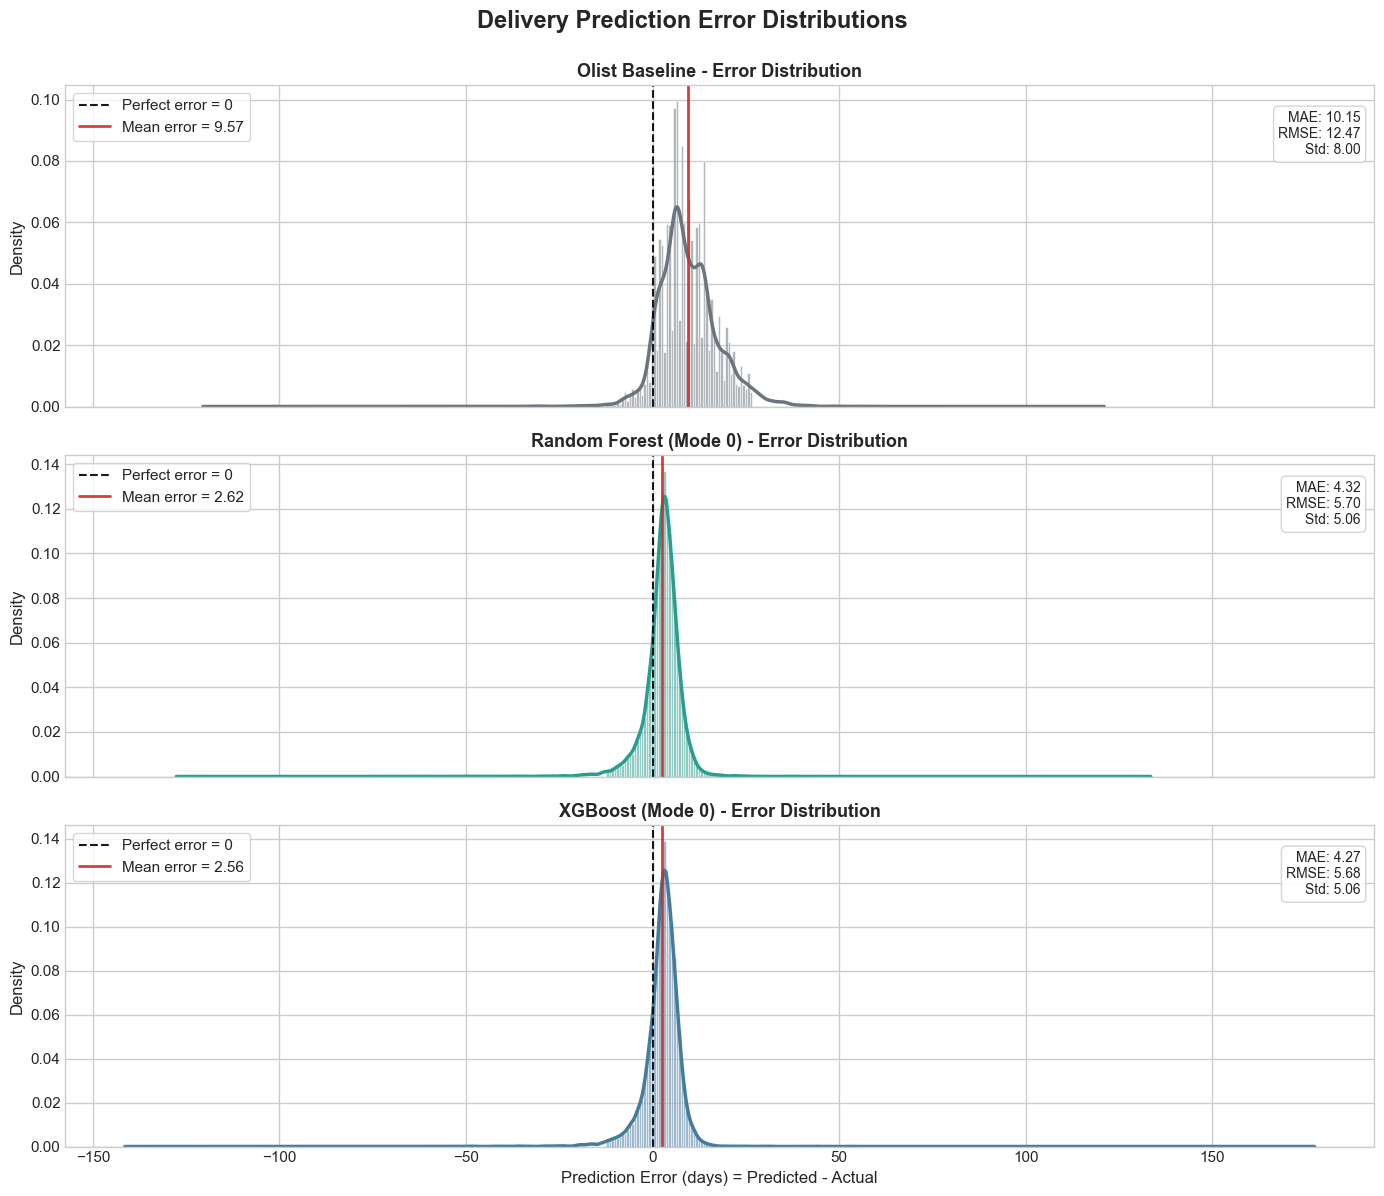

In [35]:
# Appendix A16 -- Error distributions
err_olist = df_test['estimated_delivery_days'].to_numpy() - y_test.to_numpy()
err_rf    = pred_rf - y_test.to_numpy()
err_xgb   = pred_xgb - y_test.to_numpy()

errors = [
    ('Olist Baseline', err_olist, '#6c757d'),
    ('Random Forest (Mode 0)', err_rf, '#2a9d8f'),
    ('XGBoost (Mode 0)', err_xgb, '#457b9d'),
]

all_err = np.concatenate([err_olist, err_rf, err_xgb])
x_min, x_max = np.percentile(all_err, [1, 99])
bins = np.linspace(x_min, x_max, 60)

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

for ax, (name, e, color) in zip(axes, errors):
    s = pd.Series(e)
    ax.hist(e, bins=bins, density=True, alpha=0.55, color=color, edgecolor='white', linewidth=0.8)
    s.plot(kind='kde', ax=ax, color=color, linewidth=2.5)
    ax.axvline(0, color='black', linestyle='--', linewidth=1.5, alpha=0.9, label='Perfect error = 0')
    ax.axvline(s.mean(), color='#d62828', linestyle='-', linewidth=2, alpha=0.9, label=f'Mean error = {s.mean():.2f}')
    mae = np.mean(np.abs(e))
    rmse = np.sqrt(np.mean(e**2))
    ax.text(
        0.99, 0.92,
        f'MAE: {mae:.2f}\nRMSE: {rmse:.2f}\nStd: {s.std():.2f}',
        transform=ax.transAxes,
        ha='right', va='top',
        fontsize=10,
        bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='lightgray', alpha=0.95)
    )
    ax.set_title(f'{name} - Error Distribution', fontsize=13, fontweight='bold')
    ax.set_ylabel('Density')
    ax.legend(loc='upper left', frameon=True)

axes[-1].set_xlabel('Prediction Error (days) = Predicted - Actual')
fig.suptitle('Delivery Prediction Error Distributions', fontsize=17, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()